In [1]:
import pandas as pd

import sys
sys.path.append('../')

%load_ext autoreload
%autoreload 2

from libs import ios
from libs import vis
from libs.inference import categorical
from libs.inference import numeric
from libs import constants
from libs import utils
from libs import tools_comparison as tc
from libs.bibs import aps

Total combinations of features: 1023


# Setup

In [2]:
vis.sns_reset()
vis.sns_paper_style()

## Constants

In [3]:
VERSION = 3

RS_REG = 1
ID_REG = 224
METRIC_REG = 'mean'

RS_CLAS = 1
CUT_CLAS = 4
ID_CLAS = 251
METRIC_CLASS = 'median'

FN_APS_DEMOGRAPHICS = '/data/datasets/APS/aps_data_processing/shares/aps-2022_25-10-01_e59319256d553035c40188457bb16edbfe02da04.zip' #aps_20240130_2e52fdd7260ea462878821948a2a463ed9acb58a.zip'

FN_CNKI_GIVENNAMES_GENDER = f'../../results/v{VERSION}/gender/pinyin_infer/uniqueChineseAllGivenNames_PYgender.csv'
FN_CNKI_GROUND_TRUTH = f'../../data/v{VERSION}/annotations/gender/{constants.FN_ANNOTATIONS}'
FN_CNKI_GROUND_TRUTH_REG_SAMPLED = f'../../results/v{VERSION}/gender/predictions/comparison/rs{RS_REG}/regression/_{METRIC_REG}/{constants.FN_GT_TRAN_TEST_SAMPLE}'
FN_CNKI_GROUND_TRUTH_CLAS_SAMPLED = f'../../results/v{VERSION}/gender/predictions/comparison/rs{RS_CLAS}/classification/_{METRIC_CLASS}/cut_{CUT_CLAS}/{constants.FN_GT_TRAN_TEST_SAMPLE}'


In [4]:
RESULTS_DIR = f'../../results/v{VERSION}/gender/'
ios.validate_path(RESULTS_DIR)

In [48]:
GT_METRICS = {'regression': 'mean', 'classification': 'median'}

METHOD_LABELS = {
        "gender_clean": "Karimi et al. (2016)",
        "gender_nq_clean": "Buskirk et al. (2023)",
        "pred_label": "Ours",
        "majority_label": "Ours (majority vote)",
        'pred': 'Ours',
        "gender": "Ground-truth",
    }

METHOD_ORDER = ['gender_clean', 'gender_nq_clean', 'pred_label', 'majority_label', 'pred', 'gender']

PINYIN_AGG_LABELS = {'gender_avg_all': 'Mean (all chars)', 
                     'gender_weighted_pop_NU': 'Weighted pop.', 
                     'gender_avg_CNKI': 'Mean (CNKI chars)', 
                     'gender_weighted_pop_CNKI': 'Weighted CNKI pop.'}

## Loading data

In [6]:
_df_aps_authors = ios.read_csv_from_zip(FN_APS_DEMOGRAPHICS, 'data/authors.csv')
_df_aps_authors_names = ios.read_csv_from_zip(FN_APS_DEMOGRAPHICS, 'data/author_names.csv')
_df_aps_genders = ios.read_csv_from_zip(FN_APS_DEMOGRAPHICS, 'data/genders.csv')

df_aps = pd.merge(_df_aps_authors, _df_aps_authors_names, how='inner', on='id_author', suffixes=("_a","_n"))
df_aps = pd.merge(df_aps, _df_aps_genders, how='left', on='id_gender')
df_aps = df_aps[['id_author','id_author_name','name','gender','gender_nq', 'disambiguated']] # NOTE: it contains disambiguated True and False

print(f"APS authors: {_df_aps_authors.shape}")
print(f"APS authors names: {_df_aps_authors_names.shape}")
print(f"APS genders: {_df_aps_genders.shape}")
print(f"APS all authors merged: {df_aps.shape}")


APS authors: (874556, 4)
APS authors names: (948771, 4)
APS genders: (3, 2)
APS all authors merged: (948771, 6)


In [7]:
df_cnki_gender = ios.load_csv(FN_CNKI_GIVENNAMES_GENDER)
print(f"CNKI given names with gender: {df_cnki_gender.shape}")


CNKI given names with gender: (46144, 18)


In [8]:
df_cnki_gender.sample(2)

,givenname,pred,pred_label,pop_CNKI,pop_NU,NLen,english_one,unique_name_count,gender_weighted_pop_CNKI,gender_weighted_pop_NU,gender_avg_all,gender_avg_CNKI,male_label_count,female_label_count,neutral_label_count,pop_sum_CNKI,pop_sum_NU,givennames
27126,新毅,0.165359,male,1,3727.206849,2,xinyi,22,0.590162,0.513039,0.523754,0.523754,7,12,3,33,38733.026409,信义#信谊#心宜#心怡#心颐#忻怡#新义#新夷#新怡#新懿#新毅#新邑#昕仪#昕怡#欣宜#欣...
3504,涴,0.313467,male,0,0.000001,1,wan,32,0.522699,0.404066,0.406445,0.544749,23,5,4,19,3889.987676,万#丸#剜#塆#婉#婠#完#宛#弯#惋#挽#晚#椀#涴#湾#烷#玩#琬#畹#皖#碗#箢#纨#...


In [9]:
df_gt = ios.load_csv(FN_CNKI_GROUND_TRUTH)
df_gt.shape

(166, 14)

In [10]:
df_gt.sample(2)

,givenname,a1,a2,a3,a4,a5,a6,a7,a8,a9,a10,a11,single_char,round
139,硕,3.0,2.0,1.0,2.0,3.0,2.0,3.0,1.0,2.0,3.0,3.0,True,2
100,舒会,5.0,2.0,4.0,4.0,3.0,3.0,2.0,4.0,4.0,4.0,5.0,False,1


In [11]:
df_reg = ios.load_csv(FN_CNKI_GROUND_TRUTH_REG_SAMPLED)
df_reg.loc[:, 'pinyin_givenname'] = df_reg.givenname.apply(lambda n: utils.characternames_handler.pinyin_givename([n])[0])
df_reg.shape

(166, 14)

In [12]:
df_reg.sample(2)

,givenname,ngender_mean,single_char,ngender_r,ngender_n,gender_n,gender_w,gender_nw,mean_ngender_rnw,mean_ngender_rn,mean_ngender_rw,mean_ngender_nw,ml_sample,pinyin_givenname
116,治秀,0.625000,False,0.58235,0.461152,male,female,neutral,0.681167,0.521751,0.791175,0.730576,train,zhixiu
138,祥旭,0.208333,False,0.17430,0.391868,male,male,male,0.188723,0.283084,0.087150,0.195934,test,xiangxu


In [13]:
df_clas = ios.load_csv(FN_CNKI_GROUND_TRUTH_CLAS_SAMPLED)
df_clas.loc[:, 'pinyin_givenname'] = df_clas.givenname.apply(lambda n: utils.characternames_handler.pinyin_givename([n])[0])
df_clas.shape

(166, 14)

In [14]:
df_clas.sample(2)

,givenname,gender_median,single_char,ngender_r,ngender_n,gender_n,gender_w,gender_nw,mean_ngender_rnw,mean_ngender_rn,mean_ngender_rw,mean_ngender_nw,ml_sample,pinyin_givenname
17,润,neutral,True,0.48830,0.547711,female,unknown,female,NaN,0.518005,NaN,NaN,train,run
55,中伦,male,False,0.16845,0.324024,male,male,male,0.164158,0.246237,0.084225,0.162012,test,zhonglun


## Pre-processing

In [ ]:
# APS
df_aps_clean = aps.clean_aps_names(df_aps)
df_aps_clean_ch_py = aps.detect_pinyin_and_chinese_names(df_aps_clean)
df_aps_clean_ch_py.loc[:, 'gender_nq_clean'] = df_aps_clean_ch_py.loc[:, 'gender_nq_clean'].replace({'gf': 'female', 'gm': 'male'})

df_aps_clean_ch_py.shape, df_aps.shape


((874556, 21), (948771, 6))

In [104]:
data_aps_gender_ch = (
                        df_aps_clean_ch_py.query("ch_givenname.notna()")
                        .groupby("ch_givenname", as_index=False)
                        .agg(
                            genders=("genders", lambda s: s.dropna().tolist()),
                            genders_nq=("genders_nq", lambda s: s.dropna().tolist()),
                            gender_clean=("gender_clean", aps._resolve_gender),
                            gender_nq_clean=("gender_nq_clean", aps._resolve_gender),
                        )
                    )


data_aps_gender_ch.shape[0] * 100 / df_aps_clean_ch_py.shape[0]

0.19198313201212958

In [105]:
data_aps_gender_py = (
                        df_aps_clean_ch_py.query("is_pinyin == True")
                        .groupby("givenname_clean", as_index=False)
                        .agg(
                            genders=("genders", lambda s: s.dropna().tolist()),
                            genders_nq=("genders_nq", lambda s: s.dropna().tolist()),
                            gender_clean=("gender_clean", aps._resolve_gender),
                            gender_nq_clean=("gender_nq_clean", aps._resolve_gender),
                        )
                    )
                    
data_aps_gender_py.shape[0] * 100 / df_aps_clean_ch_py.shape[0]

1.0122850909490073

In [91]:
data_cnki_gender_ch = df_cnki_gender.copy()
data_cnki_gender_ch.shape

(46144, 18)

In [92]:
data_cnki_gender_ch.sample(2)

,givenname,pred,pred_label,pop_CNKI,pop_NU,NLen,english_one,unique_name_count,gender_weighted_pop_CNKI,gender_weighted_pop_NU,gender_avg_all,gender_avg_CNKI,male_label_count,female_label_count,neutral_label_count,pop_sum_CNKI,pop_sum_NU,givennames
25982,振奎,0.159080,male,1,2629.267992,2,zhenkui,2,0.159080,0.159080,0.159080,0.159080,2,0,0,2,3758.063907,振奎#振魁
6207,觫,0.313467,male,0,0.000001,1,su,28,0.476968,0.661608,0.351225,0.398219,20,1,7,26,5704.654002,俗#傃#僳#嗉#塑#夙#宿#愫#涑#溯#甦#稣#窣#簌#粟#素#肃#苏#蔌#觫#诉#谡#蹜#...


In [93]:
# all unique pinyin forms in cnki
df_cnki_gender_unique_pinyins = df_cnki_gender.drop_duplicates(subset=['english_one'], keep='first').copy()
df_cnki_gender_unique_pinyins.loc[:, 'majority_label'] = df_cnki_gender_unique_pinyins.apply(lambda row: categorical.infer_gender_by_majority_vote(row.male_label_count, row.female_label_count, row.neutral_label_count), axis=1)

# necessary columns
cols = ['givenname', 'english_one', 'pred', 'gender_weighted_pop_CNKI', 'gender_weighted_pop_NU', 'gender_avg_all', 'gender_avg_CNKI', 'pred_label', 'majority_label']
data_cnki_gender_py = df_cnki_gender_unique_pinyins[cols].copy()
data_cnki_gender_py.shape

(18740, 9)

In [94]:
data_cnki_gender_py.sample(2)

,givenname,english_one,pred,gender_weighted_pop_CNKI,gender_weighted_pop_NU,gender_avg_all,gender_avg_CNKI,pred_label,majority_label
24009,德懋,demao,0.15908,0.16222,0.164875,0.16222,0.16222,male,male
23066,廷武,tingwu,0.15908,0.15908,0.159080,0.15908,0.15908,male,male


In [95]:
# adding pinyin form
df_gt.loc[:, 'pinyin_givenname'] = df_gt.givenname.apply(lambda n: utils.characternames_handler.pinyin_givename([n])[0])

# Adding the ground-truth metrics from the annotations
annotation_cols = [c for c in df_gt.columns if c.startswith('a') and type(eval(c[1:])) == int]
for _, metric in GT_METRICS.items():
    df_gt.loc[:, metric] = df_gt[annotation_cols].agg(metric, axis=1)
    df_gt.loc[:, metric] = df_gt.loc[:, metric].apply(lambda v: tc.scale_1_to_5_to_0_to_1(v))

# Adding labels (cut 4: 0.3, 0.7 using median)
df_gt.loc[:, 'gender'] = df_gt.apply(lambda row: 'male' if row['median'] < 0.3 else 'female' if row['median'] > 0.7 else 'neutral', axis=1)

df_gt.shape

(166, 18)

In [96]:
df_gt.sample(5)

,givenname,a1,a2,a3,a4,a5,a6,a7,a8,a9,a10,a11,single_char,round,pinyin_givenname,mean,median,gender
52,旭炜,1.0,1.0,1.0,2.0,1.0,1.0,2.0,1.0,1.0,1.0,1.0,False,1,xuwei,0.045455,0.00,male
72,滟滪,5.0,4.0,4.0,5.0,4.0,4.0,4.0,5.0,5.0,5.0,5.0,False,1,yanyu,0.886364,1.00,female
67,法新,2.0,2.0,3.0,2.0,3.0,2.0,2.0,2.0,1.0,2.0,1.0,False,1,faxin,0.250000,0.25,male
86,硕涵,3.0,2.0,2.0,4.0,3.0,4.0,3.0,4.0,5.0,1.0,1.0,False,1,shuohan,0.477273,0.50,neutral
152,认,3.0,3.0,2.0,2.0,3.0,2.0,3.0,2.0,3.0,3.0,3.0,True,2,ren,0.409091,0.50,neutral


# Analysis

## Chinese character

In [107]:
# CHINESE CHARS 
data_gt_ch = df_gt.copy()

# Addint predictions
data_gt_ch = data_gt_ch.set_index('givenname').join(data_cnki_gender_ch.set_index('givenname'), how='left')

# adding training/test split
data_gt_ch = data_gt_ch.join(df_reg.set_index('givenname')[['ml_sample']], how='left')

# adding aps
data_gt_aps_ch = data_gt_ch.reset_index().query("givenname in @data_aps_gender_ch.ch_givenname").copy()
data_gt_aps_ch = data_gt_aps_ch.set_index('givenname').join(data_aps_gender_ch.set_index('ch_givenname'), how='left').copy()

data_gt_ch.shape, data_gt_aps_ch.shape, df_gt.shape

((166, 35), (7, 39), (166, 18))


========== test set ==========


/home/espinl/.conda/envs/py12chinam/lib/python3.12/site-packages/sklearn/metrics/_regression.py:1211: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)


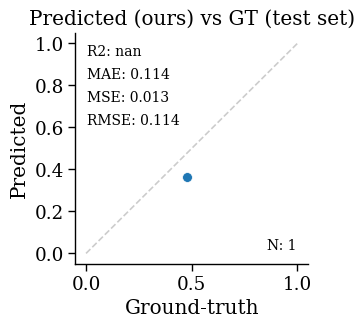


========== all GT ==========


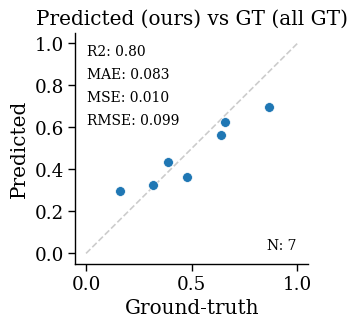

In [108]:
for setname, df in [('test set', data_gt_aps_ch.query("ml_sample == 'test'")), ('all GT', data_gt_aps_ch)]:
    print(f"\n========== {setname} ==========")
    mae_pred_ch, mse_pred_ch, rmse_pred_ch, r2_pred_ch = numeric.get_performance(df, 'mean', 'pred')
    performance_ch = {'mae': mae_pred_ch, 'mse': mse_pred_ch, 'rmse': rmse_pred_ch, 'r2': r2_pred_ch}
    _, _ = vis.plot_regression_performance(df, 'mean', 'pred', 
                                    metrics = performance_ch,
                                    figsize=(3, 3), 
                                    title=f"Predicted (ours) vs GT ({setname})", 
                                    xlabel="Ground-truth", 
                                    ylabel="Predicted",
                                    markersize=50,
                                    markeralpha=1.0,
                                    )

    if setname == 'test set':
        rmse_pred_ch_test = rmse_pred_ch

    vis.plt.show()
    vis.plt.close()



========== test set ==========


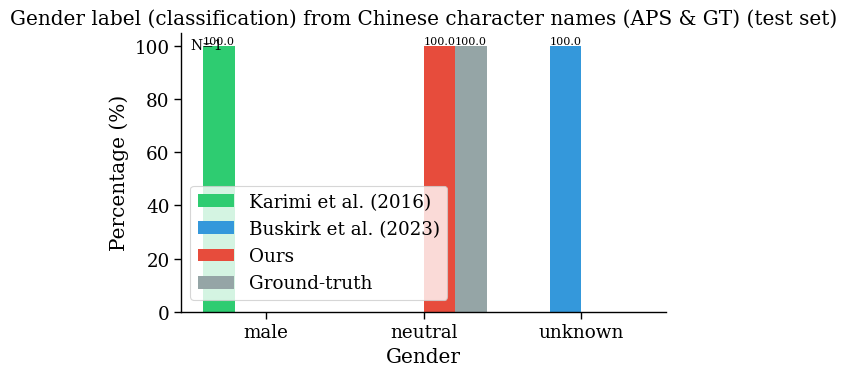


========== all GT ==========


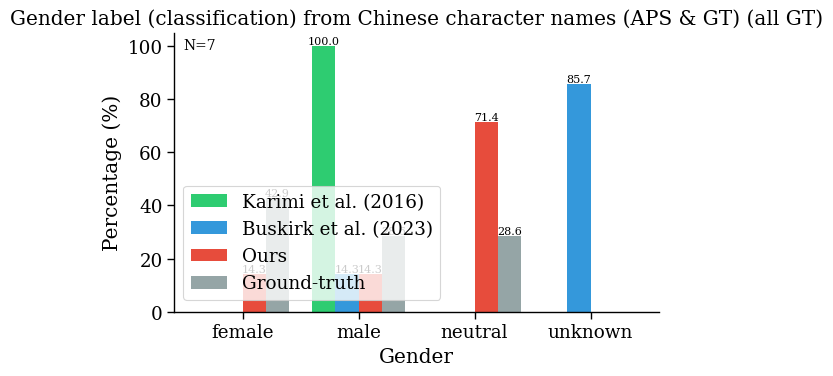

In [109]:
for setname, df in [('test set', data_gt_aps_ch.query("ml_sample == 'test'")), ('all GT', data_gt_aps_ch)]:
    print(f"\n========== {setname} ==========")
    fig, ax = vis.plot_gender_comparison(
        df,
        method_order=['gender_clean','gender_nq_clean', "pred_label", 'gender'],
        method_labels=METHOD_LABELS,
        xlabel_order=["female", "male", "neutral", "unknown"],
        colors=["#2ecc71", "#3498db", "#e74c3c", "#95a5a6"],
        use_percentages=True,
        annotate_bars=True,
        title=f"Gender label (classification) from Chinese character names (APS & GT) ({setname})",
        n_annotation_kwargs={"fontsize": 10, "x": 0.02, "y":0.98, "ha": "left"} ,
        legend_kwargs={"loc": "lower left", "bbox_to_anchor": (0.0, 0.01)}
    )
    vis.plt.show()
    vis.plt.close()

In [128]:
# Agreement between gender inference methods provided by APS and ours
method_cols = ['gender_clean','gender_nq_clean',"pred_label", 'gender']

for setname, df in [('test set', data_gt_aps_ch.query("ml_sample == 'test'")), ('all GT', data_gt_aps_ch)]:
    print(f"\n========== {setname} ==========")

    # 1) Pairwise agreement (accuracy) matrix — proportion of rows where methods agree:
    agreement_gt_ch = categorical.pairwise_agreement(df, method_cols)
    print("Pairwise agreement (accuracy) matrix — proportion of rows where methods agree:")
    display(agreement_gt_ch.round(2))

    # 2) Cohen's Kappa — agreement corrected for chance
    kappa_gt_ch = categorical.pairwise_kappa(df, method_cols)
    print("\nCohen's Kappa matrix (chance-corrected agreement):")
    display(kappa_gt_ch.round(2))

    if setname == 'test set':
        agreement_gt_ch_test = agreement_gt_ch
        kappa_gt_ch_test = kappa_gt_ch



========== test set ==========
Pairwise agreement (accuracy) matrix — proportion of rows where methods agree:


,gender_clean,gender_nq_clean,pred_label,gender
gender_clean,1.0,0.0,0.0,0.0
gender_nq_clean,0.0,1.0,0.0,0.0
pred_label,0.0,0.0,1.0,1.0
gender,0.0,0.0,1.0,1.0



Cohen's Kappa matrix (chance-corrected agreement):


/home/espinl/.conda/envs/py12chinam/lib/python3.12/site-packages/sklearn/metrics/_classification.py:730: RuntimeWarning: invalid value encountered in scalar divide
  k = np.sum(w_mat * confusion) / np.sum(w_mat * expected)
/home/espinl/.conda/envs/py12chinam/lib/python3.12/site-packages/sklearn/metrics/_classification.py:730: RuntimeWarning: invalid value encountered in scalar divide
  k = np.sum(w_mat * confusion) / np.sum(w_mat * expected)
/home/espinl/.conda/envs/py12chinam/lib/python3.12/site-packages/sklearn/metrics/_classification.py:730: RuntimeWarning: invalid value encountered in scalar divide
  k = np.sum(w_mat * confusion) / np.sum(w_mat * expected)
/home/espinl/.conda/envs/py12chinam/lib/python3.12/site-packages/sklearn/metrics/_classification.py:730: RuntimeWarning: invalid value encountered in scalar divide
  k = np.sum(w_mat * confusion) / np.sum(w_mat * expected)
/home/espinl/.conda/envs/py12chinam/lib/python3.12/site-packages/sklearn/metrics/_classification.py:730: Run

,gender_clean,gender_nq_clean,pred_label,gender
gender_clean,NaN,0.0,0.0,0.0
gender_nq_clean,0.0,NaN,0.0,0.0
pred_label,0.0,0.0,NaN,NaN
gender,0.0,0.0,NaN,NaN



========== all GT ==========
Pairwise agreement (accuracy) matrix — proportion of rows where methods agree:


,gender_clean,gender_nq_clean,pred_label,gender
gender_clean,1.00,0.14,0.14,0.29
gender_nq_clean,0.14,1.00,0.00,0.00
pred_label,0.14,0.00,1.00,0.57
gender,0.29,0.00,0.57,1.00



Cohen's Kappa matrix (chance-corrected agreement):


/home/espinl/.conda/envs/py12chinam/lib/python3.12/site-packages/sklearn/metrics/_classification.py:730: RuntimeWarning: invalid value encountered in scalar divide
  k = np.sum(w_mat * confusion) / np.sum(w_mat * expected)


,gender_clean,gender_nq_clean,pred_label,gender
gender_clean,NaN,0.00,0.00,0.00
gender_nq_clean,0.0,1.00,-0.02,-0.04
pred_label,0.0,-0.02,1.00,0.38
gender,0.0,-0.04,0.38,1.00


In [127]:
labels = ['female', 'male', 'neutral', 'unknown']
normalize = 'true' # pred, all


for setname, df in [('test set', data_gt_aps_ch.query("ml_sample == 'test'")), ('all GT', data_gt_aps_ch)]:
    print(f"\n========== {setname} ==========")
    
    for col in ['gender_clean', 'gender_nq_clean', 'pred_label']:

        print(f"========== {col} ==========")

        cm, precision, recall, f1, _, accuracy = categorical.get_performance(df, col_true='gender', col_pred=col, labels=labels, normalize=normalize)
        
        print("\nConfusion matrix:")
        display(cm.round(2))

        print("\nPrecision:")
        for label, prec in zip(labels, precision.round(2)):
            print(f"- {label}: {prec:.2f}")
        
        print("\nRecall:")
        for label, prec in zip(labels, recall.round(2)):
            print(f"- {label}: {prec:.2f}")
        
        
        print("\nF1 score:")
        for label, prec in zip(labels, f1.round(2)):
            print(f"- {label}: {prec:.2f}")
        

        print(f"\nAccuracy: {accuracy:.2f}")
    


========== test set ==========
========== gender_clean ==========

Confusion matrix:


array([[0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 1., 0., 0.],
       [0., 0., 0., 0.]])


Precision:
- female: 0.00
- male: 0.00
- neutral: 0.00
- unknown: 0.00

Recall:
- female: 0.00
- male: 0.00
- neutral: 0.00
- unknown: 0.00

F1 score:
- female: 0.00
- male: 0.00
- neutral: 0.00
- unknown: 0.00

Accuracy: 0.00
========== gender_nq_clean ==========

Confusion matrix:


array([[0., 0., 0., 0.],
       [0., 0., 0., 0.],
       [0., 0., 0., 1.],
       [0., 0., 0., 0.]])


Precision:
- female: 0.00
- male: 0.00
- neutral: 0.00
- unknown: 0.00

Recall:
- female: 0.00
- male: 0.00
- neutral: 0.00
- unknown: 0.00

F1 score:
- female: 0.00
- male: 0.00
- neutral: 0.00
- unknown: 0.00

Accuracy: 0.00
========== pred_label ==========

Confusion matrix:


...


Precision:
- female: 0.00
- male: 0.29
- neutral: 0.00
- unknown: 0.00

Recall:
- female: 0.00
- male: 1.00
- neutral: 0.00
- unknown: 0.00

F1 score:
- female: 0.00
- male: 0.44
- neutral: 0.00
- unknown: 0.00

Accuracy: 0.29
========== gender_nq_clean ==========

Confusion matrix:


array([[0.  , 0.33, 0.  , 0.67],
       [0.  , 0.  , 0.  , 1.  ],
       [0.  , 0.  , 0.  , 1.  ],
       [0.  , 0.  , 0.  , 0.  ]])


Precision:
- female: 0.00
- male: 0.00
- neutral: 0.00
- unknown: 0.00

Recall:
- female: 0.00
- male: 0.00
- neutral: 0.00
- unknown: 0.00

F1 score:
- female: 0.00
- male: 0.00
- neutral: 0.00
- unknown: 0.00

Accuracy: 0.00
========== pred_label ==========

Confusion matrix:


array([[0.33, 0.  , 0.67, 0.  ],
       [0.  , 0.5 , 0.5 , 0.  ],
       [0.  , 0.  , 1.  , 0.  ],
       [0.  , 0.  , 0.  , 0.  ]])


Precision:
- female: 1.00
- male: 1.00
- neutral: 0.40
- unknown: 0.00

Recall:
- female: 0.33
- male: 0.50
- neutral: 1.00
- unknown: 0.00

F1 score:
- female: 0.50
- male: 0.67
- neutral: 0.57
- unknown: 0.00

Accuracy: 0.57


## Pinyin

In [113]:
# Make pinyin_givenname unique: average mean/median, majority-vote gender
def _gender_majority_vote(series):
    counts = series.value_counts()
    male = int(counts.get('male', 0))
    female = int(counts.get('female', 0))
    neutral = int(counts.get('neutral', 0))
    total = male + female + neutral
    if total == 0:
        return 'neutral'
    return categorical.infer_gender_by_majority_vote(male, female, neutral)

df_gt_py = (
    df_gt[['pinyin_givenname', 'mean', 'median', 'gender']]
    .groupby('pinyin_givenname', as_index=False)
    .agg(
        mean=('mean', 'mean'),
        median=('median', 'mean'),
        gender=('gender', _gender_majority_vote),
    )
)

df_gt_py.shape

(162, 4)

In [114]:
# PINYIN
data_gt_py = df_gt_py.copy()

# Addint predictions
data_gt_py = data_gt_py.set_index('pinyin_givenname').join(data_cnki_gender_py.drop_duplicates('english_one', keep='first').drop(columns=['givenname']).set_index('english_one'), how='left')

# adding training/test split
data_gt_py = data_gt_py.join(df_reg.set_index('pinyin_givenname')[['ml_sample']], how='left')

# adding aps
data_gt_aps_py = data_gt_py.reset_index().query("pinyin_givenname in @data_aps_gender_py.givenname_clean").copy()
data_gt_aps_py = data_gt_aps_py.set_index('pinyin_givenname').join(data_aps_gender_py.set_index('givenname_clean'), how='left').copy()

data_gt_py.shape, data_gt_aps_py.shape, df_gt.shape

((166, 11), (116, 15), (166, 18))

========== gender_weighted_pop_NU ==========


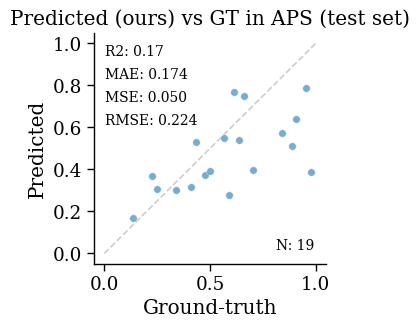

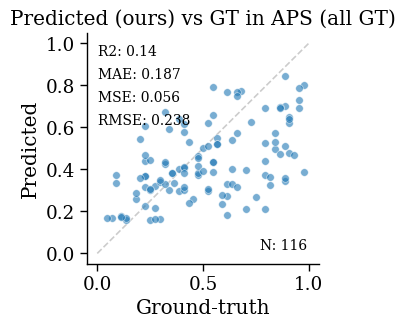

========== gender_weighted_pop_CNKI ==========


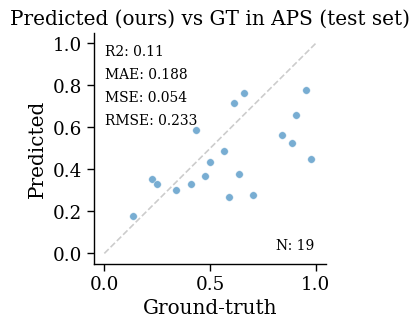

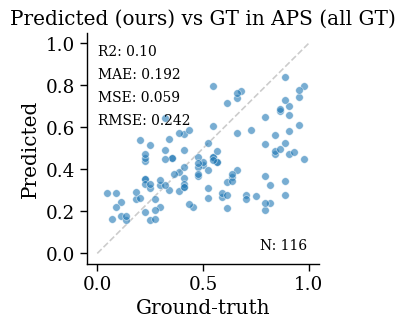

========== gender_avg_all ==========


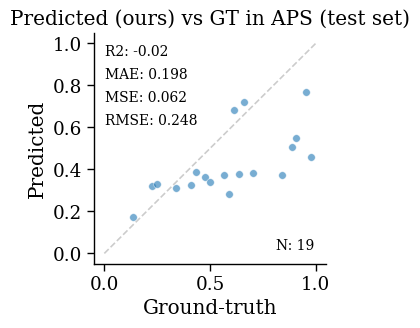

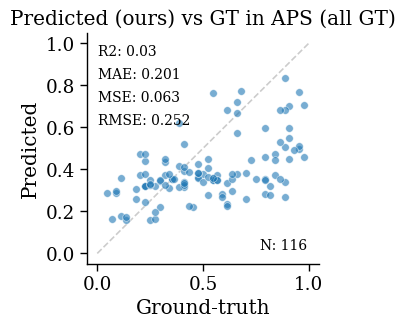

========== gender_avg_CNKI ==========


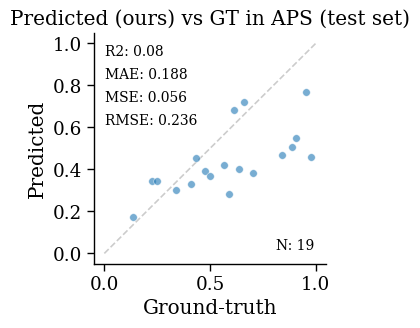

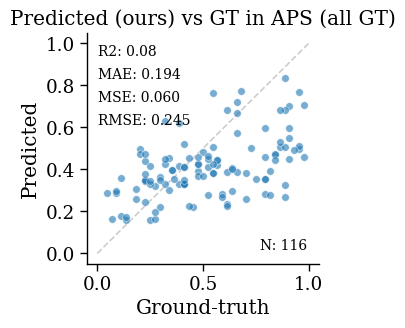

In [115]:
rmse_pred_py_test = None

for col in ['gender_weighted_pop_NU', 'gender_weighted_pop_CNKI', 'gender_avg_all', 'gender_avg_CNKI']:

    print(f"========== {col} ==========")

    for setname, df in [('test set', data_gt_aps_py.query("ml_sample == 'test'")), ('all GT', data_gt_aps_py)]:
        
        df = df.dropna(subset=[col])
        
        mae_pred, mse_pred, rmse_pred, r2_pred = numeric.get_performance(df, 'mean', col)
        performance_py = {'mae': mae_pred, 'mse': mse_pred, 'rmse': rmse_pred, 'r2': r2_pred}

        if setname == 'test set':
            if rmse_pred_py_test is None:
                rmse_pred_py_test = (rmse_pred, col)
            elif rmse_pred < rmse_pred_py_test[0]:
                rmse_pred_py_test = (rmse_pred, col)

        _, _ = vis.plot_regression_performance(df, 'mean', col, 
                                        metrics = performance_py,
                                        figsize=(3, 3), 
                                        title=f"Predicted (ours) vs GT in APS ({setname})", 
                                        xlabel="Ground-truth", 
                                        ylabel="Predicted",
                                        markersize=30,
                                        markeralpha=0.6,
                                        )
        vis.plt.show()
        vis.plt.close()


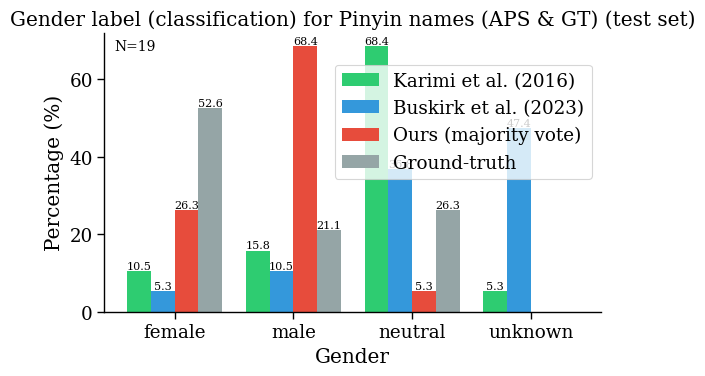

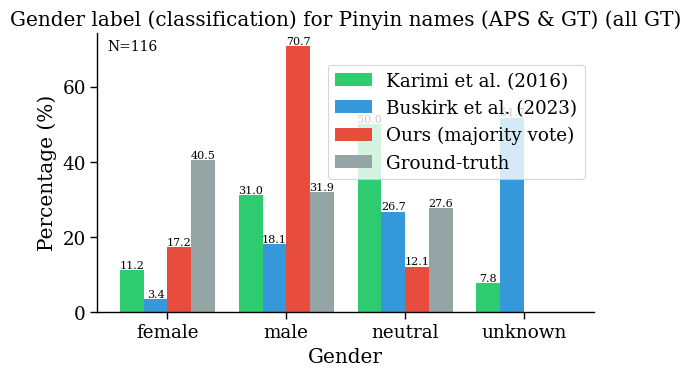

In [118]:
for setname, df in [('test set', data_gt_aps_py.query("ml_sample == 'test'")), ('all GT', data_gt_aps_py)]:

    fig, ax = vis.plot_gender_comparison(
        df,
        method_order=['gender_clean','gender_nq_clean',"majority_label", 'gender'],
        method_labels=METHOD_LABELS,
        xlabel_order=["female", "male", "neutral", "unknown"],
        colors=["#2ecc71", "#3498db", "#e74c3c", "#95a5a6"],
        use_percentages=True,
        annotate_bars=True,
        title=f"Gender label (classification) for Pinyin names (APS & GT) ({setname})",
        n_annotation_kwargs={"fontsize": 10, "x": 0.02, "y":0.98, "ha": "left"},
        legend_kwargs={"loc": "upper right", "bbox_to_anchor": (1.0, 0.92)}
    )
    vis.plt.show()
    vis.plt.close()

In [125]:
# Agreement between gender inference methods provided by APS and ours
method_cols = ['gender_clean','gender_nq_clean',"majority_label", 'gender']


for setname, df in [('test set', data_gt_aps_py.query("ml_sample == 'test'")), ('all GT', data_gt_aps_py)]:
    print(f"\n========== {setname} ==========")

    # 1) Pairwise agreement (accuracy) matrix — proportion of rows where methods agree:
    agreement_gt_py = categorical.pairwise_agreement(df, method_cols)
    print("Pairwise agreement (accuracy) matrix — proportion of rows where methods agree:")
    display(agreement_gt_py.round(2))

    # 2) Cohen's Kappa — agreement corrected for chance
    kappa_gt_py = categorical.pairwise_kappa(df, method_cols)
    print("\nCohen's Kappa matrix (chance-corrected agreement):")
    display(kappa_gt_py.round(2))

    if setname == 'test set':
        agreement_gt_py_test = agreement_gt_py
        kappa_gt_py_test = kappa_gt_py



========== test set ==========
Pairwise agreement (accuracy) matrix — proportion of rows where methods agree:


,gender_clean,gender_nq_clean,majority_label,gender
gender_clean,1.00,0.37,0.26,0.32
gender_nq_clean,0.37,1.00,0.11,0.21
majority_label,0.26,0.11,1.00,0.47
gender,0.32,0.21,0.47,1.00



Cohen's Kappa matrix (chance-corrected agreement):


,gender_clean,gender_nq_clean,majority_label,gender
gender_clean,1.00,0.10,0.11,0.06
gender_nq_clean,0.10,1.00,0.00,0.07
majority_label,0.11,0.00,1.00,0.25
gender,0.06,0.07,0.25,1.00



========== all GT ==========
Pairwise agreement (accuracy) matrix — proportion of rows where methods agree:


,gender_clean,gender_nq_clean,majority_label,gender
gender_clean,1.00,0.36,0.33,0.40
gender_nq_clean,0.36,1.00,0.17,0.23
majority_label,0.33,0.17,1.00,0.45
gender,0.40,0.23,0.45,1.00



Cohen's Kappa matrix (chance-corrected agreement):


,gender_clean,gender_nq_clean,majority_label,gender
gender_clean,1.00,0.17,0.04,0.16
gender_nq_clean,0.17,1.00,0.01,0.10
majority_label,0.04,0.01,1.00,0.18
gender,0.16,0.10,0.18,1.00


In [120]:
labels = ['female', 'male', 'neutral', 'unknown']
normalize = 'true' # pred, all

col = 'majority_label'

for setname, df in [('test set', data_gt_aps_py.query("ml_sample == 'test'")), ('all GT', data_gt_aps_py)]:
    cm, precision, recall, f1, _, accuracy = categorical.get_performance(df, col_true='gender', col_pred=col, labels=labels, normalize=normalize)

    print(f"\n========== {col} ==========")
    print("\nConfusion matrix:")
    display(cm.round(2))

    print("\nPrecision:")
    for label, prec in zip(labels, precision.round(2)):
        print(f"- {label}: {prec:.2f}")

    print("\nRecall:")
    for label, prec in zip(labels, recall.round(2)):
        print(f"- {label}: {prec:.2f}")


    print("\nF1 score:")
    for label, prec in zip(labels, f1.round(2)):
        print(f"- {label}: {prec:.2f}")


    print(f"\nAccuracy: {accuracy:.2f}")
    


========== majority_label ==========

Confusion matrix:


array([[0.5, 0.4, 0.1, 0. ],
       [0. , 1. , 0. , 0. ],
       [0. , 1. , 0. , 0. ],
       [0. , 0. , 0. , 0. ]])


Precision:
- female: 1.00
- male: 0.31
- neutral: 0.00
- unknown: 0.00

Recall:
- female: 0.50
- male: 1.00
- neutral: 0.00
- unknown: 0.00

F1 score:
- female: 0.67
- male: 0.47
- neutral: 0.00
- unknown: 0.00

Accuracy: 0.47

========== majority_label ==========

Confusion matrix:


array([[0.36, 0.47, 0.17, 0.  ],
       [0.  , 0.89, 0.11, 0.  ],
       [0.09, 0.84, 0.06, 0.  ],
       [0.  , 0.  , 0.  , 0.  ]])


Precision:
- female: 0.85
- male: 0.40
- neutral: 0.14
- unknown: 0.00

Recall:
- female: 0.36
- male: 0.89
- neutral: 0.06
- unknown: 0.00

F1 score:
- female: 0.51
- male: 0.55
- neutral: 0.09
- unknown: 0.00

Accuracy: 0.45


In [121]:
data_gt_aps_ch.shape, data_gt_aps_py.shape, data_gt_aps_ch.query("ml_sample == 'test'").shape, data_gt_aps_py.query("ml_sample == 'test'").shape,

((7, 39), (116, 15), (1, 39), (19, 15))

In [129]:
metrics_ch = {'agreement': agreement_gt_ch_test.rename(index={'pred_label': 'pred'}), 'kappa': kappa_gt_ch_test.rename(index={'pred_label': 'pred'}), 'rmse': rmse_pred_ch_test, 'n': len(data_gt_aps_ch.query("ml_sample == 'test'"))}
metrics_py = {'agreement': agreement_gt_py_test.rename(index={'majority_label': 'pred'}), 'kappa': kappa_gt_py_test.rename(index={'majority_label': 'pred'}), 'rmse': rmse_pred_py_test, 'n': len(data_gt_aps_py.query("ml_sample == 'test'"))}
reference_col = 'gender'
decimal_places = 2
group_header_labels = ("Chinese", "Pinyin")
title = "Comparison of gender label inference performance for Chinese-character and Pinyin name representations."
caption = r"Performance of our two models evaluated against human-annotated ground truth, including 7 authors matched via Chinese-character records and 116 via Pinyin representations. Our framework comprises a regression model that produces continuous gender scores, evaluated using RMSE, and a classification model that produces four labels (female, male, neutral, unknown), evaluated using accuracy and Cohen's $\kappa$ which measures agreement beyond chance given the observed class distribution. Karimi et al. and Buskirk et al. provide three labels (female, male, unknown) and do not produce continuous scores. They do not support inference from Chinese characters; for these cases, predictions are derived from the genders inferred for the corresponding Pinyin representation. For Pinyin-based inference in our method, scores are aggregated across all Chinese characters mapping to the same Pinyin form and weighted by population frequency (\Cref{sec:methods}). Our method achieves the highest classification performance across both name representations, and both models attain lower error for Chinese-character names than for Pinyin names, reflecting the stronger gender specificity of individual characters compared with shared Pinyin forms."
row_order = ['gender_clean', 'gender_nq_clean', "majority_label", 'pred_label', 'pred']

eval_tbl = categorical.comparison_table_to_latex(
    metrics_ch,
    metrics_py,
    reference_col,
    row_labels = METHOD_LABELS,
    row_order = row_order,
    title = title,
    caption = caption,
    decimal_places = decimal_places,
    group_header_labels = group_header_labels
)

print(eval_tbl)

[INFO] Pinyin aggregation: gender_weighted_pop_NU
\begin{table}[htbp]
\centering
\caption{\textbf{Comparison of gender label inference performance for Chinese-character and Pinyin name representations.} Performance of our two models evaluated against human-annotated ground truth, including 7 authors matched via Chinese-character records and 116 via Pinyin representations. Our framework comprises a regression model that produces continuous gender scores, evaluated using RMSE, and a classification model that produces four labels (female, male, neutral, unknown), evaluated using accuracy and Cohen's $\\kappa$ which measures agreement beyond chance given the observed class distribution. Karimi et al. and Buskirk et al. provide three labels (female, male, unknown) and do not produce continuous scores. They do not support inference from Chinese characters; for these cases, predictions are derived from the genders inferred for the corresponding Pinyin representation. For Pinyin-based inferenc